In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

In [3]:
def find_equilibria(dU, xlim, n=4000):
    xs = np.arange(xlim[0], xlim[1])
    f = dU(xs)
    roots = []

    for i in range(len(xs)):
        if abs(f[i]) == 0:
            roots.append(xs[i])

    roots = np.sort(np.array(roots))
    return np.array(roots)

def analyze_equilibria(d2U, roots):
    out = []
    for x in roots:
        k = float(d2U(x))
        if k > 0:
            kind, color, marker = "центр", "blue", "o"
        elif k < 0:
            kind, color, marker = "седло", "red", "x"
        out.append({
            "x": float(x),
            "Uxx": k,
            "kind": kind,
            "color": color,
            "marker": marker
        })
    return out

In [4]:
def classify_traj(x0, v0, U, xlim_class=(-10, 10), n=8000):
    E = 0.5 * v0**2 + float(U(x0))
    xs = np.linspace(xlim_class[0], xlim_class[1], n)
    acc = U(xs) <= E + 1e-8

    idx = int(np.argmin(np.abs(xs - x0))) #ближ. к х0
    l = idx
    while l > 0 and acc[l - 1]:
        l -= 1
    r = idx
    while r < n - 1 and acc[r + 1]:
        r += 1

    if l == 0 or r == n - 1:
        return "infinite", E
    return "finite", E

def classify_starts(U, initial_conditions, xlim_class=None, n=8000):
    if not initial_conditions:
        return []

    xlim_class=(-10, 10)

    results = []
    for x0, v0 in initial_conditions:
        kind, E = classify_traj(x0, v0, U, xlim_class=xlim_class, n=n)
        results.append({
            "x0": x0,
            "v0": v0,
            "E": E,
            "kind": kind,
            "color": "orange" if kind == "infinite" else "green",
        })
    return results

In [5]:
def plot_vector_field(ax, rhs, xlim, ylim, N=25):
    xs = np.linspace(xlim[0], xlim[1], N)
    ys = np.linspace(ylim[0], ylim[1], N)
    X, Y = np.meshgrid(xs, ys)

    Uv = np.zeros_like(X)
    Vv = np.zeros_like(Y)

    for i in range(N):
        for j in range(N):
            Uv[i, j], Vv[i, j] = rhs(0.0, [X[i, j], Y[i, j]])

    norm = np.hypot(Uv, Vv)
    norm[norm == 0] = 1

    ax.quiver(X, Y, Uv / norm, Vv / norm, alpha=0.35)

def plot_traj(ax, rhs, x0, v0, color, T=25):
    y0 = [x0, v0]
    for tspan in [(0, T), (0, -T)]:
        sol = solve_ivp(
            rhs, tspan, y0,
            rtol=1e-8, atol=1e-10, max_step=0.05
        )
        ax.plot(sol.y[0], sol.y[1], color=color, lw=1.2)

In [6]:
def plot_phase_portrait():
    U   = lambda x: x**5/5 - 5*x**3/3 + 4*x
    dU  = lambda x: x**4 - 5*x**2 +4
    d2U = lambda x: 4*x**3 - 10*x 
    
    xlim = (-3, 3)
    ylim = (-4, 4)

    initial_conditions = [(-2.5, 1), (-2, 1.5), (1, 1.5), (-1, 1.25), (2, 1.25), (-1, 0.35) , (2, 0.35)]

    rhs = lambda t, y: [y[1], -dU(y[0])]

    roots = find_equilibria(dU, xlim)
    eqs = analyze_equilibria(d2U, roots)

    fig, ax = plt.subplots(figsize=(8, 6))

    plot_vector_field(ax, rhs, xlim, ylim, N=25)

    saddles = [e for e in eqs if e["kind"] == "седло"]
    for s in saddles:
        xs = s["x"]
        J = np.array([[0.0, 1.0],
                    [-d2U(xs), 0.0]])
        eigenvalues, eigenvectors = np.linalg.eig(J)
        eigenvalues = eigenvalues.real
        eigenvectors = eigenvectors.real

        vec = eigenvectors[:, 0]
        vec = vec / np.linalg.norm(vec)


        y0 = np.array([xs, 0.0]) +  0.1 * vec
        for T in (+100.0, -100.0):
            sol = solve_ivp(rhs, (0, T), y0, max_step=0.05)
            ax.plot(sol.y[0], sol.y[1],
                    color="red", linestyle="--", lw=1.2)


    for e in eqs:
        if e["kind"] == "центр":
            ax.plot(e["x"], 0, "o", color="blue", zorder=6)
        elif e["kind"] == "седло":
            ax.plot(e["x"], 0, "x", color="red", zorder=6)
        else:
            ax.plot(e["x"], 0, "s", color="green", ms=8,
                    zorder=6)


    for r in classify_starts(U, initial_conditions):
        x0, v0 = r["x0"], r["v0"]
        color  = r["color"]              
        sol    = solve_ivp(rhs, (0,  50), (x0, v0), max_step=0.01)
        sol_b  = solve_ivp(rhs, (0, -50), (x0, v0), max_step=0.01)
        ax.plot(sol.y[0],   sol.y[1],   color=color, lw=1.2)
        ax.plot(sol_b.y[0], sol_b.y[1], color=color, lw=1.2)


    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xlabel("x")
    ax.set_ylabel("v")

    ax.grid(alpha=0.3)

    plt.show()
    return eqs

In [11]:
def out_of_bounds(t, y):
    return 10.0 - abs(y[0])

out_of_bounds.terminal = True  # Остановить решение
out_of_bounds.direction = -1

def times_realization():
    U   = lambda x: x**5/5 - 5*x**3/3 + 4*x
    dU  = lambda x: x**4 - 5*x**2 +4
    d2U = lambda x: 4*x**3 - 10*x 
    
    xlim = (-3, 3)
    ylim = (-4, 4)
    
    
    rhs = lambda t, y: [y[1], -dU(y[0])]
    
    roots = find_equilibria(dU, xlim)
    eqs = analyze_equilibria(d2U, roots)

    fig, ax1 = plt.subplots(figsize=(8, 6))
    fig, ax2 = plt.subplots(figsize=(8, 6))
    fig, ax3 = plt.subplots(figsize=(8, 6))
    fig, ax4 = plt.subplots(figsize=(8, 6))
    fig, ax5 = plt.subplots(figsize=(8, 6))
    fig, ax6 = plt.subplots(figsize=(8, 6))
    ax1.set_title("Сост равн")
    ax2.set_title("Финитные")
    ax3.set_title("Инфинитные")
    ax4.set_title("Лимитационные")
    ax5.set_title("Лимитно инфинитные")
    ax6.set_title("Лимитно инфинитные")
    
    for x0 in roots:
        x0 = np.round(x0)
        sol = solve_ivp(rhs, (0, 10), [x0, 0.0], max_step=0.05)
        ax1.plot(sol.t, sol.y[0])

    for x0 in (-1, 2): #финитные 
        sol_cicle = solve_ivp(rhs, (0, 10), (x0, 0.6), max_step=0.05)
        ax2.plot(sol_cicle.t, sol_cicle.y[0], color="green")


    for x0 in [ (-2.0, 2.0), (1, 1),(-2.9,1.0)]: #инфинитные 
        sol = solve_ivp(rhs, (0, 10), x0, max_step=0.001,
                    rtol=1e-10, atol=1e-12, events=out_of_bounds)
        solb = solve_ivp(rhs, (0, -10), x0, max_step=0.001,
                    rtol=1e-10, atol=1e-12, events=out_of_bounds)
        ax3.plot(sol.t, sol.y[0],
                            color="orange", lw=1.2)
        ax3.plot(solb.t, solb.y[0],
                            color="orange", lw=1.2)
    
    saddles = [-2.0, 1.0]
    for xs in saddles:  #лимитационные (выходящие сепаратрисы)
        J = np.array([[0.0, 1.0], [-d2U(xs), 0.0]])
        eigenvalues, eigenvectors = np.linalg.eig(J)
        eigenvalues = eigenvalues.real
        eigenvectors = eigenvectors.real

        idx = np.argmax(eigenvalues)  #неустойч сепаратр
        lam = eigenvalues[idx]
        vec = eigenvectors[:, idx]
        vec = vec / np.linalg.norm(vec)

        y0 = np.array([xs, 0.0]) + 1 * 0.001 * vec
        sol = solve_ivp(rhs, (0, 7), y0, max_step=0.05, events=out_of_bounds)
        ax4.plot(sol.t, sol.y[0], lw=1.5)

    for xs in saddles: #лимитно-инфинитные (входящие сепаратрисы)
        J = np.array([[0.0, 1.0], [-d2U(xs), 0.0]])
        eigenvalues, eigenvectors = np.linalg.eig(J)
        eigenvalues = eigenvalues.real
        eigenvectors = eigenvectors.real


        idx = np.argmin(eigenvalues)
        lam = eigenvalues[idx]
        vec = eigenvectors[:, idx]
        vec = vec / np.linalg.norm(vec)


        y0 = np.array([xs, 0.0]) + 1 * 0.001 * vec
        sol = solve_ivp(rhs, (0, -10), y0, max_step=0.05, events=out_of_bounds)
        ax5.plot(sol.t, sol.y[0], lw=1.5, label=f"Выход из x={xs}")
        y0 = np.array([xs, 0.0]) + 1 * 0.001 * -1*vec
        sol = solve_ivp(rhs, (0, 10), y0, max_step=0.05, events=out_of_bounds)
        ax6.plot(sol.t, sol.y[0], lw=1.5, label=f"Выход из x={xs}")


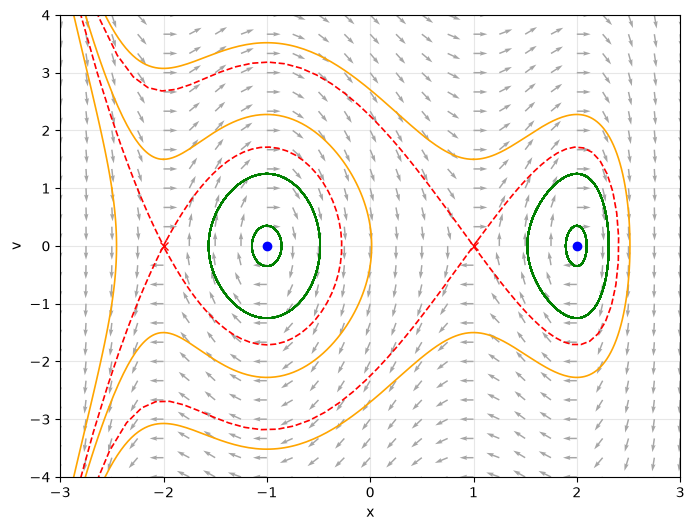


Найденные положения равновесия:
x* = -2, U''(x*) = -12, тип = седло
x* = -1, U''(x*) = 6, тип = центр
x* = 1, U''(x*) = -6, тип = седло
x* = 2, U''(x*) = 12, тип = центр


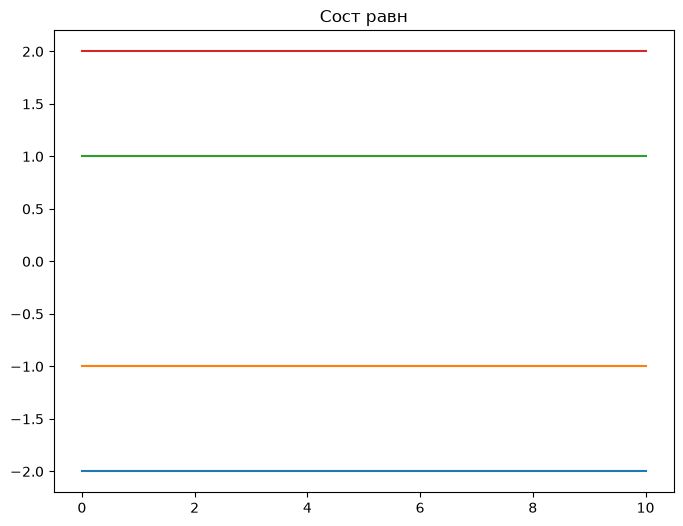

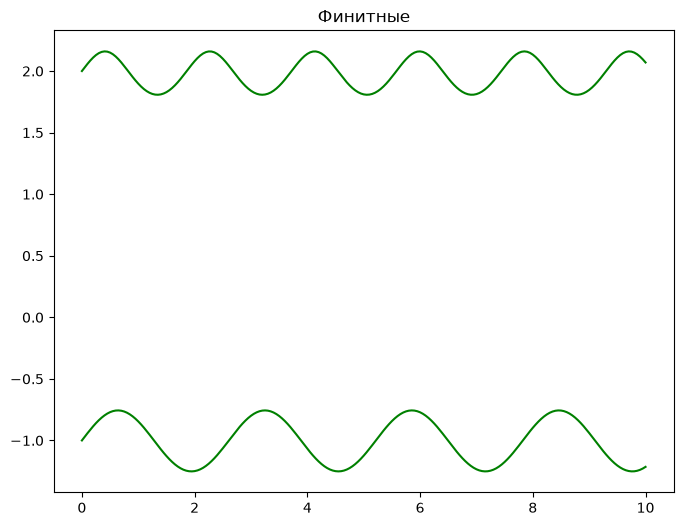

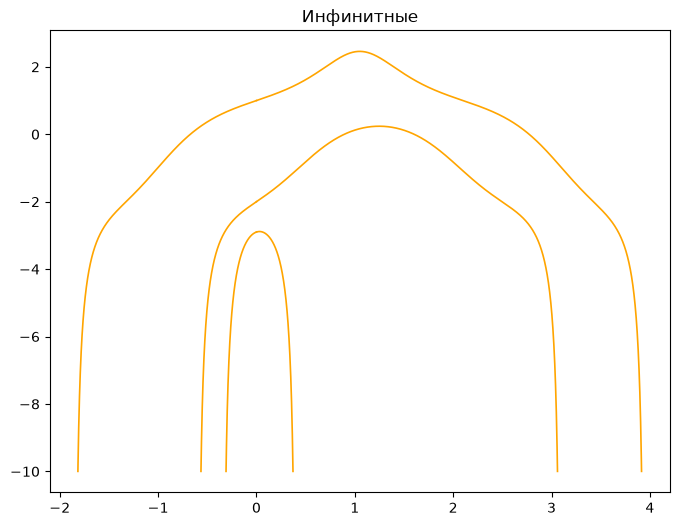

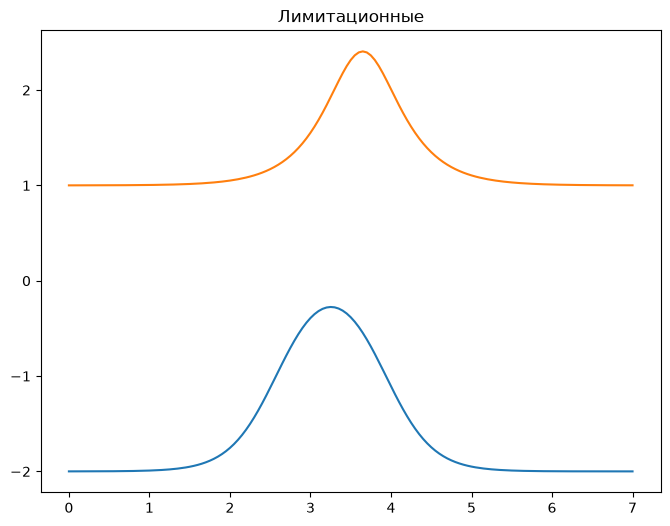

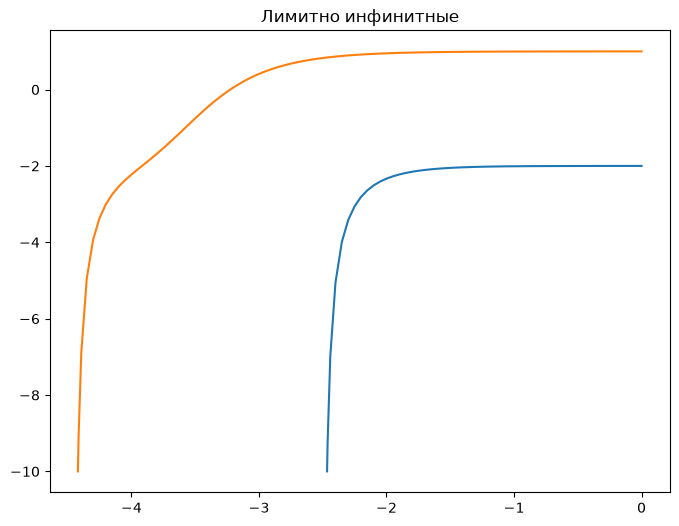

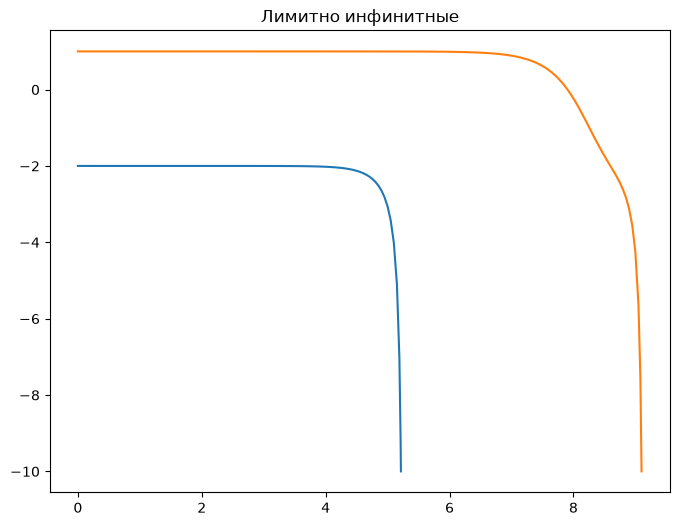

In [12]:
eqs = plot_phase_portrait()
times_realization()

print("\nНайденные положения равновесия:")
for e in eqs:
    print(
        f"x* = {e['x']:.8g}, "
        f"U''(x*) = {e['Uxx']:.8g}, "
        f"тип = {e['kind']}"
    )
    